
# An Analysis of Color and RGB Values

**Name:** Aiyanna Ranch
**Date:** November 10, 2026  
**Dataset:** Colors Dataset

## Introduction

For this project, I chose a dataset containing different colors and their corresponding RGB values. I chose this dataset because I am interested in exploring how colors differ numerically and how they can be grouped into different categories. Color is something we encounter every day, but the numerical values behind different colors provide an interesting opportunity for data analysis.

Each observation in this dataset represents an individual color. The dataset includes the color's name, hexadecimal code, RGB values, and assigned category.

The variables I plan to investigate include red, green, and blue intensity, along with the categorical variable representing each color's classification.

**Research Question:** How do RGB intensity values differ across different color categories?

**Hypothesis:** I hypothesize that different color categories will demonstrate noticeably different RGB intensity patterns. Specifically, warm colors will generally have higher red intensity values, while cool colors will tend to have higher blue intensity values.


In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
with open("colors.json", "r") as file:
    colors_data = json.load(file)

colors_data.keys()

dict_keys(['colors'])

In [5]:
colors_df = pd.json_normalize(colors_data["colors"])

colors_df.head()

,name,hex,category,rgb.r,rgb.g,rgb.b
0,Black,#000000,neutral,0,0,0
1,White,#FFFFFF,neutral,255,255,255
2,Red,#FF0000,primary,255,0,0
3,Green,#00FF00,primary,0,255,0
4,Blue,#0000FF,primary,0,0,255


In [6]:
colors_df.shape

(35, 6)

In [7]:
colors_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   name      35 non-null     str  
 1   hex       35 non-null     str  
 2   category  35 non-null     str  
 3   rgb.r     35 non-null     int64
 4   rgb.g     35 non-null     int64
 5   rgb.b     35 non-null     int64
dtypes: int64(3), str(3)
memory usage: 2.4 KB


In [8]:
colors_df.describe()

,rgb.r,rgb.g,rgb.b
count,35.000000,35.000000,35.000000
mean,157.600000,141.600000,131.114286
std,100.781126,97.005518,93.533816
min,0.000000,0.000000,0.000000
25%,69.500000,31.000000,46.000000
50%,192.000000,160.000000,130.000000
75%,255.000000,227.000000,214.500000
max,255.000000,255.000000,255.000000



## Data Preparation

After loading the JSON file, I converted the color information into a pandas DataFrame. The original dataset contained RGB values inside a nested dictionary, so I used pd.json_normalize to separate the red, green, and blue values into individual columns.

The dataset contains 35 observations and six variables. The red, green, and blue columns are quantitative variables, while the name, hexadecimal code, and category columns contain categorical or identifying information. No observations were removed during the preparation process.

In [9]:
colors_df.columns

Index(['name', 'hex', 'category', 'rgb.r', 'rgb.g', 'rgb.b'], dtype='str')

In [10]:
colors_df = colors_df.rename(columns={
    "rgb.r": "red",
    "rgb.g": "green",
    "rgb.b": "blue"
})

colors_df.head()

,name,hex,category,red,green,blue
0,Black,#000000,neutral,0,0,0
1,White,#FFFFFF,neutral,255,255,255
2,Red,#FF0000,primary,255,0,0
3,Green,#00FF00,primary,0,255,0
4,Blue,#0000FF,primary,0,0,255


Renaming the columns so it is easier to work with.

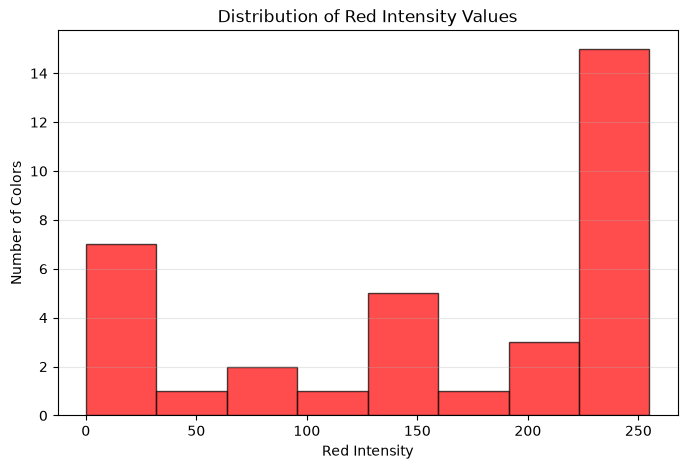

In [11]:
plt.figure(figsize=(8, 5))

plt.hist(colors_df["red"], bins=8, color="red", edgecolor="black", alpha=0.7)

plt.title("Distribution of Red Intensity Values")
plt.xlabel("Red Intensity")
plt.ylabel("Number of Colors")
plt.grid(axis="y", alpha=0.3)

plt.show()

### Histogram Analysis

The histogram displays the distribution of red intensity values across the 35 colors in the dataset. Each bar represents the number of colors that fall within a particular range of red intensity. This visualization is useful because it allows me to see how red values are distributed and whether certain ranges occur more frequently than others.

The choice of bins affects how the data is displayed. Using fewer bins provides a broader overview of the distribution, while using more bins allows for a closer look at individual ranges. This histogram provides an initial understanding of how red intensity varies throughout the dataset.

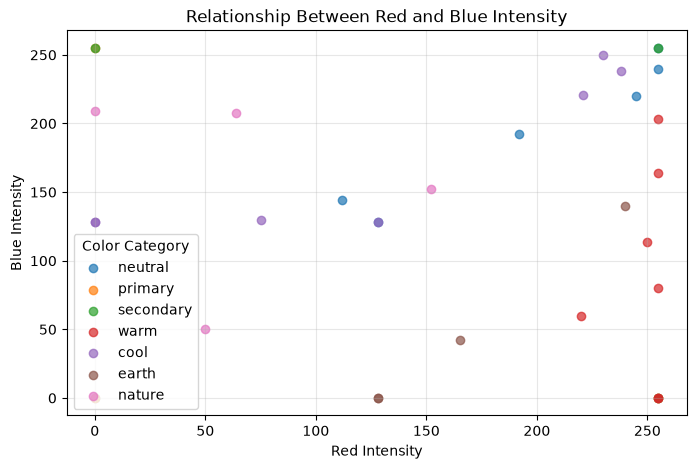

In [12]:
plt.figure(figsize=(8, 5))

for category in colors_df["category"].unique():
    category_data = colors_df[colors_df["category"] == category]
    plt.scatter(
        category_data["red"],
        category_data["blue"],
        label=category,
        alpha=0.7
    )

plt.title("Relationship Between Red and Blue Intensity")
plt.xlabel("Red Intensity")
plt.ylabel("Blue Intensity")
plt.legend(title="Color Category")
plt.grid(alpha=0.3)

plt.show()

### Scatter Plot Analysis

The scatter plot compares red and blue intensity values across the different colors in the dataset. Each point represents an individual color, while the different colors distinguish the assigned categories. This visualization is useful because it allows me to examine whether red and blue intensity have any noticeable relationship.

I can also use this graph to identify differences between color categories. Colors with higher red intensity may appear toward the right side of the graph, while colors with higher blue intensity appear toward the top. Comparing the placement of these points helps illustrate how different color categories have different RGB characteristics.

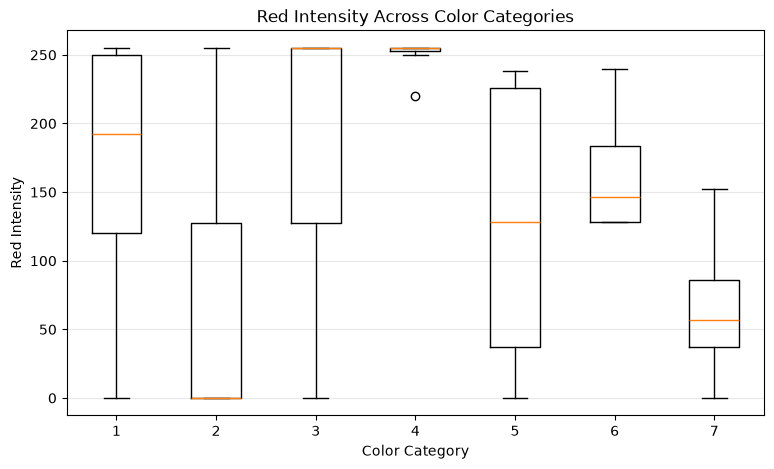

In [15]:
plt.figure(figsize=(9, 5))

categories = colors_df["category"].unique()

boxplot_data = [
    colors_df[colors_df["category"] == category]["red"]
    for category in categories
]

plt.boxplot(boxplot_data, label=categories)

plt.title("Red Intensity Across Color Categories")
plt.xlabel("Color Category")
plt.ylabel("Red Intensity")
plt.grid(axis="y", alpha=0.3)

plt.show()

### Boxplot Analysis

The boxplot compares red intensity values across the different color categories. This visualization is useful because it displays the median, spread, and variation of red intensity within each group. It also makes it easier to identify categories that have higher or lower red intensity overall.

By comparing the boxes and their median lines, I can examine whether certain categories consistently contain higher red values than others. The boxplot provides another way to investigate my original hypothesis by showing how red intensity differs between groups.

In [16]:
plt.style.use("ggplot")

### Visualization Design Decisions

I made several design choices to improve the readability and presentation of my visualizations. I used consistent figure sizes, descriptive titles, and clearly labeled axes so that each graph would be easy to understand. I also incorporated different colors and transparency to make the data easier to distinguish.

Gridlines were added to help viewers compare values more accurately. For the scatter plot, I used a legend to identify the different color categories. These design choices help communicate the information more effectively while keeping the visualizations organized and consistent.

In [18]:
correlation = colors_df["red"].corr(colors_df["blue"])

print("Correlation between red and blue:", correlation)

Correlation between red and blue: 0.04851683314095482


In [19]:
colors_df[["red", "green", "blue"]].corr()

,red,green,blue
red,1.000000,0.20785,0.048517
green,0.207850,1.00000,0.253010
blue,0.048517,0.25301,1.000000


### Statistical Analysis

I used correlation analysis to investigate the relationships between red, green, and blue intensity values. The results showed that red and green had a weak positive correlation of approximately 0.208. Green and blue also had a weak positive correlation of approximately 0.253. Red and blue had an almost nonexistent positive correlation of approximately 0.049.

These results suggest that the intensity of one RGB component does not strongly predict the intensity of another. Green and blue had the strongest relationship, although it was still relatively weak. Red and blue had the weakest relationship, indicating very little linear association between the two variables.

Overall, these findings suggest that RGB intensity values vary somewhat independently within this dataset. The results provide a better understanding of how different colors are numerically represented. One limitation of correlation analysis is that it only measures linear relationships and does not establish causation. Additionally, the dataset contains only 35 observations, which limits the ability to generalize these findings to a larger collection of colors.

## Conclusion

After analyzing the Colors Dataset, I gained a better understanding of how RGB intensity values differ and how they contribute to the representation of individual colors. My visualizations allowed me to examine the distribution of red intensity and compare RGB values across different color categories.

My correlation analysis revealed that the relationships between red, green, and blue were relatively weak, with red and blue having the weakest correlation at approximately 0.049. These findings showed that RGB components do not necessarily increase together. Although my results provided insight into color composition, they did not fully confirm my original hypothesis about warm and cool colors.

One limitation of this project was the relatively small dataset of 35 colors. A larger dataset could provide more opportunities to identify patterns and differences between categories. Overall, this project helped me understand how Python can be used to organize, visualize, and analyze numerical data.